# 01. Data Understanding: Telco Customer Churn

**Before this notebook:** read `notes/01_data_understanding.md`.

**Goal:** get to know the dataset before we change anything. By the end you will know the dataset's size, its features, its target, the type of each column, and one hidden problem we will fix in notebook 02.

**What we do here**
1. Import libraries and load the data
2. Look at the rows
3. Check the shape and data types
4. Separate features from the target
5. Study the target (class balance)
6. Group columns by type
7. Summary statistics
8. Spot a hidden problem
9. Exercise

## Step 1: Import libraries and load the data

- `pandas` is the library for working with tables. We import it as `pd` (a universal convention).
- `pathlib.Path` builds file paths that work on any operating system.

In [1]:
import pandas as pd
from pathlib import Path

# The notebook lives in notebooks/01_supervised_churn/, so the data is two folders up.
DATA_PATH = Path("../../data/raw/telco_customer_churn.csv")

df = pd.read_csv(DATA_PATH)   # read the CSV file into a DataFrame (a table)
print("Loaded OK")

Loaded OK


**Line by line**
- `DATA_PATH = Path(...)`: stores the file location in a variable. `..` means "go up one folder".
- `pd.read_csv(DATA_PATH)`: reads a CSV file and returns a **DataFrame**. *Input:* a file path. *Output:* a table with rows and named columns.
- We call the table `df`, a common short name for DataFrame.

**Expected output:** `Loaded OK`. A `FileNotFoundError` means the path is wrong, so check where you opened Jupyter from.

## Step 2: Look at the data

`df.head()` shows the first 5 rows. Always look at real rows with your own eyes.

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**What to notice**
- Each row is one customer. Each column is one fact about them.
- `customerID` looks like a random code. It is an **identifier**.
- `Churn` is the last column. It says `Yes` or `No`. This is our **target**.
- Many columns hold text such as `Yes`, `No`, `DSL` and `Month-to-month`. These are **categorical** features.
- `tenure` (months as a customer), `MonthlyCharges` and `TotalCharges` look like numbers.

To see all 21 columns without Jupyter hiding the middle ones, we can transpose the first rows:

In [3]:
df.head(3).T   # .T flips rows and columns so each column name is on its own line

,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


## Step 3: Shape and data types

In [4]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (7043, 21)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  

**Line by line**
- `df.shape`: a tuple `(rows, columns)`. *Not* a function, so there are no brackets after `shape`.
- `df.info()`: prints each column's name, how many **non-null** (filled in) values it has, and its **dtype**.

**How to read the output**
- `7043 rows, 21 columns`: 7,043 customers.
- Every column shows `7043 non-null`, so Pandas sees **no missing values**. Keep this in mind, we will test it later.
- `int64` = whole numbers, `float64` = decimals, `object` or `str` = text (the name depends on your Pandas version).
- **Surprise:** `TotalCharges` should be a number (a total in dollars), yet it is listed as **text**. Something is wrong with it. We come back to this in Step 8.

## Step 4: Features and target

In supervised learning we split the table into two parts:
- **X** (features): what the model looks at.
- **y** (target): what the model must predict.

We do this split of *columns* now only to understand the data. Splitting *rows* into training and test sets comes in notebook 05.

In [5]:
target_col = "Churn"
id_col = "customerID"

y = df[target_col]                              # the target: one column
X = df.drop(columns=[target_col, id_col])       # the features: everything except target and ID

print("X shape:", X.shape)
print("y shape:", y.shape)
print()
print("Feature names:")
print(list(X.columns))

X shape: (7043, 19)
y shape: (7043,)

Feature names:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


**Line by line**
- `df[target_col]`: selects one column. The result is a **Series** (a single column with an index).
- `df.drop(columns=[...])`: returns a *new* table without the listed columns. The original `df` is unchanged.
- Why drop `customerID`? It is unique for every customer, so it has no pattern to learn. It would only let a model memorise rows.

**Expected output:** `X` has 19 columns (21 minus target minus ID) and `y` has 7,043 values.

**Common mistake:** forgetting to remove the target from `X`. Then the model sees the answer, which is cheating and called *data leakage*.

## Step 5: Study the target

Is it more common for customers to stay or leave? This is the **class balance**.

In [6]:
print("Counts:")
print(y.value_counts())
print()
print("Percentages:")
print((y.value_counts(normalize=True) * 100).round(1))

Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentages:
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


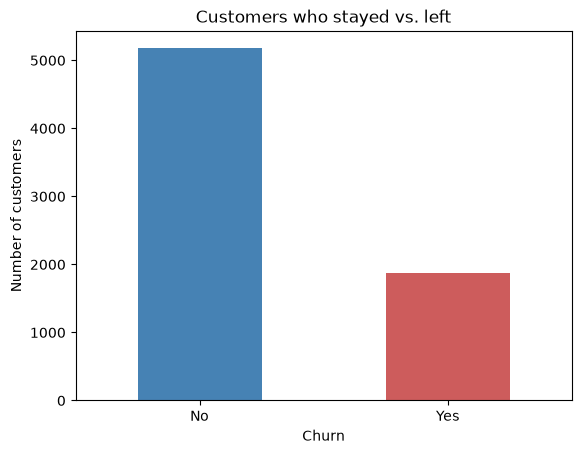

In [7]:
import matplotlib.pyplot as plt

y.value_counts().plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Customers who stayed vs. left")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.show()

**Line by line**
- `value_counts()`: counts how many times each value appears.
- `normalize=True`: gives fractions instead of counts. Multiplying by 100 gives percentages.
- `.plot(kind="bar")`: draws a bar chart straight from a Series. `plt.show()` displays it.

**How to read the output**
- About **73% No** (stayed) and **27% Yes** (left).
- This is **class imbalance**: the classes are not 50/50.
- *Why it matters:* a lazy model that predicts "No" for everyone would be about 73% accurate and catch **zero** churners. So later we won't judge models by accuracy alone. We will use precision, recall, F1 and ROC-AUC.
- This is mild imbalance. It is not a disaster, but it means we should split the data in a *stratified* way later (notebook 05).

## Step 6: Group the columns by type

Different types of columns need different treatment later:
- **Numerical** → may need scaling.
- **Categorical** → must be encoded into numbers.

In [8]:
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

print(f"Numeric columns ({len(numeric_cols)}):", numeric_cols)
print()
print(f"Categorical columns ({len(categorical_cols)}):", categorical_cols)

Numeric columns (3): ['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns (16): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


**Line by line**
- `select_dtypes(include="number")`: keeps only columns whose dtype is numeric.
- `exclude="number"`: keeps everything else.
- `.columns.tolist()`: turns the column names into a plain Python list.

**How to read the output**
- Only 3 numeric columns appear: `SeniorCitizen`, `tenure`, `MonthlyCharges`.
- The categorical list has 16 names, but **`TotalCharges` is wrongly in it**, because it is stored as text. This confirms the problem from Step 3. The other 15 are real categories.
- `SeniorCitizen` is stored as 0/1. It is numeric in storage but really a Yes/No category. We will remember this when we do encoding.

## Step 7: Summary statistics

In [9]:
df[numeric_cols].describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


**How to read the output** (one column per feature)
- `count`: how many values. `mean`: average. `std`: how spread out the values are.
- `min`, `25%`, `50%` (the median), `75%`, `max`: the values at those positions after sorting.
- `tenure` ranges from 0 to 72 months. A customer with tenure 0 is brand new.
- `MonthlyCharges` ranges roughly from 18 to 119 dollars.
- The columns have very different ranges (0-1, 0-72, 18-119). Some algorithms are sensitive to this, so we will scale them in notebook 06.

## Step 8: Spot the hidden problem in `TotalCharges`

`TotalCharges` should be a number but Pandas stored it as text. Let's find out why.

In [10]:
# pd.to_numeric turns text into numbers. errors="coerce" turns anything that fails into NaN (missing).
converted = pd.to_numeric(df["TotalCharges"], errors="coerce")

bad_rows = df[converted.isna()]
print("Rows that cannot be converted:", len(bad_rows))
bad_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows that cannot be converted: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Line by line**
- `pd.to_numeric(..., errors="coerce")`: tries to convert each value to a number. Values that fail become `NaN` ("not a number", Pandas' marker for missing).
- `converted.isna()`: gives True where a value is missing.
- `df[mask]`: keeps only the rows where the mask is True.

**What we found**
- There are **11 rows** where `TotalCharges` is a blank space `" "`. A blank is *text*, so Pandas did not count it as missing and the whole column became text.
- All 11 have `tenure = 0`. They are brand-new customers who have not been billed yet, so a blank total makes sense.
- This is why "no missing values" in `info()` was misleading: **hidden missing values**.

We do **not** fix it here. Fixing belongs to notebook 02 (data cleaning). Here we only observe and record.

## Summary of what we learned

| Question | Answer |
|---|---|
| Size | 7,043 rows × 21 columns |
| Problem type | Binary classification |
| Target | `Churn` (Yes/No), about 73% / 27% |
| Identifier | `customerID` (drop from features) |
| Numeric features | `SeniorCitizen`, `tenure`, `MonthlyCharges` (+ `TotalCharges`, once fixed) |
| Categorical features | 15 true categories (the 16th text column listed is `TotalCharges`, which is really a number) |
| Problem found | `TotalCharges` has 11 hidden blanks, stored as text |

**Next:** `02_data_cleaning` fixes the hidden missing values and checks for duplicates.

---
## Exercise

Write the code for each task in the cells below.

1. Print how many customers have `Contract` equal to `"Month-to-month"`, `"One year"` and `"Two year"` (hint: `value_counts()`).
2. Find the **average `MonthlyCharges`** for customers who churned vs. those who did not (hint: `df.groupby("Churn")["MonthlyCharges"].mean()`).
3. In one sentence, write what you think the answer to (2) means for the business.
4. **Think:** `SeniorCitizen` has values 0 and 1. Is it numerical or categorical in meaning? Why?

Try it yourself first. A solution file will be saved in `exercises/` when you are ready.

In [11]:
# Exercise 1

In [12]:
# Exercise 2